In [1]:
!pip install -q datasets scikit-learn seaborn

In [2]:
from datasets import load_dataset
import numpy as np
from PIL import Image
from collections import defaultdict

dataset = load_dataset(
    "AIOmarRehan/Vehicles",
    split="train",
    streaming=True
)

print(dataset.features)

README.md:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Auto Rickshaws', 'Bikes', 'Cars', 'Motorcycles', 'Planes', 'Ships', 'Trains'])}


In [3]:
class_names = [
    "Auto Rickshaws",
    "Bikes",
    "Cars",
    "Motorcycles"
]

X = []
y = []

counts = defaultdict(int)

dataset = dataset.shuffle(seed=42, buffer_size=2000)

for item in dataset:

    label = item["label"]

    if isinstance(label, int):
        label = dataset.features["label"].int2str(label)

    if label in class_names and counts[label] < 150:

        img = item["image"].convert("RGB")
        img = img.resize((96, 96))

        X.append(np.array(img))
        y.append(class_names.index(label))

        counts[label] += 1

    if all(counts[c] >= 150 for c in class_names):
        break

X = np.array(X, dtype="float32")
y = np.array(y)

print("Image shape:", X.shape)
print("Labels shape:", y.shape)
print("Class counts:", dict(counts))

Image shape: (600, 96, 96, 3)
Labels shape: (600,)
Class counts: {'Motorcycles': 150, 'Auto Rickshaws': 150, 'Bikes': 150, 'Cars': 150}


In [4]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

X = X / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

y_train_cat = to_categorical(y_train, 4)
y_test_cat = to_categorical(y_test, 4)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (480, 96, 96, 3)
Testing images: (120, 96, 96, 3)


In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn = models.Sequential([
    layers.Input(shape=(96, 96, 3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(4, activation='softmax')
])

cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,732,292 (6.61 MB)

 Trainable params: 1,732,292 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history_cnn = cnn.fit(
    X_train,
    y_train_cat,
    epochs=3,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

cnn_loss, cnn_acc = cnn.evaluate(X_test, y_test_cat)

print("CNN Test Accuracy:", cnn_acc * 100)

Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 389ms/step - accuracy: 0.2708 - loss: 1.4005 - val_accuracy: 0.3229 - val_loss: 1.3537
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 318ms/step - accuracy: 0.4245 - loss: 1.3024 - val_accuracy: 0.6354 - val_loss: 1.1395
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 320ms/step - accuracy: 0.5729 - loss: 1.1025 - val_accuracy: 0.5938 - val_loss: 0.9601
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.5167 - loss: 1.0743
CNN Test Accuracy: 51.66666507720947


In [7]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

mobilenet = models.Sequential([
    layers.Input(shape=(96, 96, 3)),

    layers.Rescaling(255.0),
    layers.Lambda(lambda x: tf.keras.applications.mobilenet_v2.preprocess_input(x)),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

mobilenet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
history_mobilenet = mobilenet.fit(
    X_train,
    y_train_cat,
    epochs=3,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

mobile_loss, mobile_acc = mobilenet.evaluate(
    X_test, y_test_cat
)

print("MobileNetV2 Test Accuracy:", mobile_acc * 100)

Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 277ms/step - accuracy: 0.7422 - loss: 0.6691 - val_accuracy: 0.9688 - val_loss: 0.0897
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - accuracy: 0.9818 - loss: 0.0860 - val_accuracy: 0.9688 - val_loss: 0.0754
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.9766 - loss: 0.0614 - val_accuracy: 0.9792 - val_loss: 0.0407
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.9667 - loss: 0.1427
MobileNetV2 Test Accuracy: 96.66666388511658


In [9]:
from tensorflow.keras.applications import EfficientNetB0

base_eff = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_eff.trainable = False

efficientnet = models.Sequential([
    layers.Input(shape=(96, 96, 3)),

    layers.Rescaling(255.0),

    base_eff,

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

efficientnet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

efficientnet.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
history_eff = efficientnet.fit(
    X_train,
    y_train_cat,
    epochs=3,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

eff_loss, eff_acc = efficientnet.evaluate(
    X_test, y_test_cat
)

print("EfficientNetB0 Test Accuracy:", eff_acc * 100)

Epoch 1/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 383ms/step - accuracy: 0.7396 - loss: 0.7053 - val_accuracy: 0.9688 - val_loss: 0.1453
Epoch 2/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 229ms/step - accuracy: 0.9505 - loss: 0.1642 - val_accuracy: 0.9896 - val_loss: 0.0581
Epoch 3/3
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 295ms/step - accuracy: 0.9766 - loss: 0.0841 - val_accuracy: 0.9896 - val_loss: 0.0416
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 169ms/step - accuracy: 0.9417 - loss: 0.2235
EfficientNetB0 Test Accuracy: 94.16666626930237


In [11]:
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'CNN',
        'MobileNetV2',
        'EfficientNetB0'
    ],

    'Accuracy (%)': [
        cnn_acc * 100,
        mobile_acc * 100,
        eff_acc * 100
    ],

    'Loss': [
        cnn_loss,
        mobile_loss,
        eff_loss
    ]
})

print(results)

best_model = results.loc[
    results['Accuracy (%)'].idxmax()
]

print("\nBest Model:", best_model['Model'])
print("Best Accuracy:", best_model['Accuracy (%)'])

            Model  Accuracy (%)      Loss
0             CNN     51.666665  1.074335
1     MobileNetV2     96.666664  0.142745
2  EfficientNetB0     94.166666  0.223472

Best Model: MobileNetV2
Best Accuracy: 96.66666388511658


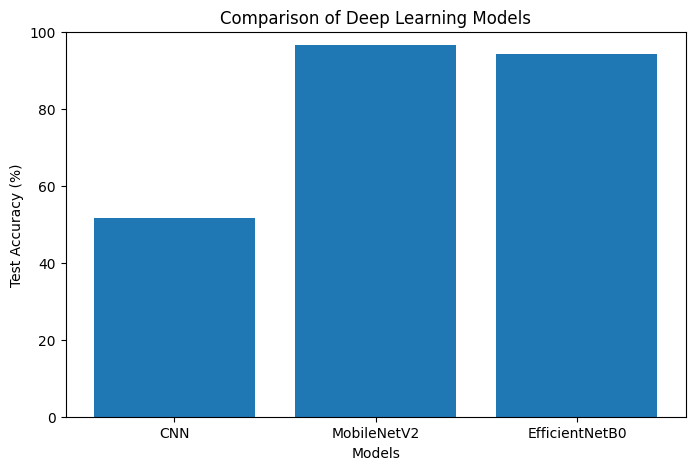

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    results['Model'],
    results['Accuracy (%)']
)

plt.title("Comparison of Deep Learning Models")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step


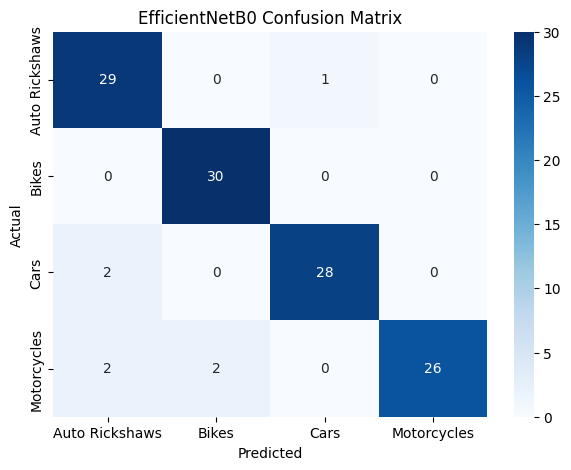

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

predictions = efficientnet.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 Confusion Matrix")

plt.show()

Saving img-20230717-wa0005~2-01-01~2-01[1].jpeg to img-20230717-wa0005~2-01-01~2-01[1].jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 767ms/step
Predicted Vehicle: Cars
Confidence: 95.1 %


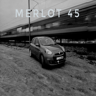

In [14]:
from google.colab import files
from PIL import Image
import numpy as np

uploaded = files.upload()

best_models = {
    "CNN": cnn,
    "MobileNetV2": mobilenet,
    "EfficientNetB0": efficientnet
}

best_model_name = best_model['Model']
model = best_models[best_model_name]

for filename in uploaded.keys():

    img = Image.open(filename).convert("RGB")
    img = img.resize((96, 96))

    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)

    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    print("Predicted Vehicle:", class_names[predicted_class])
    print("Confidence:", round(confidence, 2), "%")

    display(img)

In [15]:
cnn.save("CNN_model.keras")

mobilenet.save("MobileNetV2_model.keras")

efficientnet.save("EfficientNetB0_model.keras")

print("All three models saved successfully!")

All three models saved successfully!
